<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb - Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A datased based on LIDC-IDRI
  </h3>

  <p>
   The LNDb was developed as an external dataset complimentary to LIDC-IDRI. There are a few important differences between the two... While LIDC-IDRI is a project shared between 7 institutions, LNDb is a smaller dataset, belonging to a single institution - Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans - about a quarter of the size of LIDC-IDRI, and its classification method is different as well: it uses a single-blind methodology (a radiologist would read the scan once and no consensus or review between the radiologists was performed), instead of having multiple radiologists reading the same scan. This might cause a noticeable distinction in classification pattern for each radiologist; but, unlike LIDC-IDRI, the 5 participant radiologists are identified uniformly throughout the dataset as R1, R2, R3, R4 and R5.
  </p>
  <p>
   The variability in acquisition parameters is significantly lower in LNDb, as well as the subjective characterization of nodules. LNDb is overall a more clinically realistic dataset.
   </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Initial Data Analysis & Pre-Processing
  </h3>

  <p>
    To access LNDb's auxiliary functions, which will help us to visualize, understand and manipulate data, we must import the script <strong>'utils.py'</strong> and other scripts made available with the download of the dataset.
  </p>
  <p>
    The first step in our analysis of the dataset is to ensure that we can read the MetaImage <strong>.mhd/.raw</strong> medical image files - both the Computerized Tomography (CT) data and the segmentation masks are in this format. The file <strong>'utils.py'</strong> includes routines based on the SimpleITK library that allow us to... 
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Load the 3D CT images and the nodule masks.</li>
    <li style="margin-bottom: 8px;">Extract the metadata from the medical images, such as the pixel/voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
  <p>
    We also want to match scan slices to nodule coordinates. Thus, we have created a reusable function <strong>read_nods_in_scan</strong> which, for one scan metadata file LNDb-XXXX.mhd, and its corresponding image LNDb-XXXX.raw, extracts the necessary information for coordinate conversion from milimeters into pixels/voxels and vice-versa. This is possible using the origin, the spacing and transformation matrix of the scan. 
  </p>
  <p>
    This function also reads the nodule coordinates, in milimeters, and converts them to image coordinates, in pixel / cut indexes, using the origin and transformation origin of the corresponding scan. This way, we can associate these coordinates with the scan image. It also repeats the process for the nodule mask. So, we are able to quickly visualize every node and its mask in each CT Scan!
  </p>
</div>

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
from contextlib import redirect_stdout
root_path = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_path) not in sys.path: sys.path.append(str(root_path))
# Os scripts do LNDb importam-se entre si sem prefixo (ex: 'from utils import readCsv'),
# por isso a própria pasta src/mass_detect/lndb_utils também tem de estar no sys.path
lndb_utils_path = root_path / 'src' / 'mass_detect' / 'lndb_utils'
if str(lndb_utils_path) not in sys.path: sys.path.append(str(lndb_utils_path))

from src.mass_detect.lndb_utils import utils
from src.mass_detect.lndb_utils.readNoduleList import nodEqDiam
from src.mass_detect.lndb_utils.calcFleischner import calcFleischner

def find_file(name, base_folder="../data/LNDb"): # only the LNDb folder: searching all of ../data also walks the ~500k LIDC files
    results = list(Path(base_folder).rglob(name))
    if not results:
        raise FileNotFoundError(f"File '{name}' not found in '{base_folder}'.")
    return str(results[0])

def read_nods_in_scan(LNDb_id, nods_table, load_images=True): #Reads one CT Scan and returns array, metadata and scan nodules with converted coordinates.
    # load_images=False reads only the header of the CT (no voxels, no masks): enough for the coordinate conversion and much faster
    path_mhd = find_file(f'LNDb-{LNDb_id:04d}.mhd')
    if load_images:
        scan, spacing, origin, transfmat = utils.readMhd(path_mhd) # read metadata from scan, necessary for coordinate conversion
    else:
        reader = sitk.ImageFileReader()
        reader.SetFileName(path_mhd)
        reader.ReadImageInformation()
        scan, spacing, origin, transfmat = None, reader.GetSpacing(), reader.GetOrigin(), reader.GetDirection()
    transfmat_toimg, transfmat_toworld = utils.getImgWorldTransfMats(spacing, transfmat) #
    nods_scan = nods_table[nods_table['LNDbID'] == LNDb_id].copy()

    coords_img = []
    masks_img = []
    for _, line in nods_scan.iterrows():
        xyz_world = np.array([line['x'], line['y'], line['z']])
        xyz_img = utils.convertToImgCoord(xyz_world, origin, transfmat_toimg)
        coords_img.append(xyz_img)
        if not load_images: continue
        try: mask_mhd = find_file(f"LNDb-{LNDb_id:04d}_rad{int(line['RadID'])}.mhd")
        except FileNotFoundError: continue
        mask, _, _, _ = utils.readMhd(mask_mhd)
        masks_img.append(mask)

    nods_scan['x_img'] = [c[0] for c in coords_img]
    nods_scan['y_img'] = [c[1] for c in coords_img]
    nods_scan['z_img'] = [c[2] for c in coords_img]
    if load_images: nods_scan['mask'] = [m for m in masks_img]

    return scan, spacing, origin, nods_scan

ct_scan_id = 1
nods_table = pd.read_csv(find_file('trainNodules.csv'))
scan, spacing, origin, nods_scan = read_nods_in_scan(ct_scan_id, nods_table)

print(f"The CT Scan {ct_scan_id} has...\n  -> dimensions {scan.shape}\n  -> origin {origin}\n  -> spacing {spacing}\n")
print(f"For this scan, we have {len(nods_scan)} findings:")
print(nods_scan[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

The CT Scan 1 has...
  -> dimensions (328, 512, 512)
  -> origin (-158.1962890625, -309.1962890625, -297.5)
  -> spacing (0.607421875, 0.607421875, 1.0)

For this scan, we have 4 findings:
   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By the shape of the scan array, we can conclude that it has 328 cuts of 512x512 pixels. The voxel spacing (0.607, 0.607, 1.0)mm shows that the volume <strong>is not isotropic</strong> because the plane resolution is thinner than in between cuts. This is something to have in mind if we decide to resample into a uniform spacing before feature extraction - this probably makes the most sense. 
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> An isotropic volume implies that the spacing between voxels is equal in all directions (x, y, z) - in other words, each voxel is shaped like a perfect cube.
  </div>
  <p>
    Lastly, the origin indicates the coordinate of the word corresponding to the volume corner, necessary to convert nodule coordinates in further steps.
  </p>
  <p>
    Now, we must confirm visually the coordinate conversion by showing the exact cut where the nodule was annotated, with a red <strong>X</strong> in its position. Below, there is the side-by-side comparison of the original image and the annotated image with its nodules.
  </p>
</div>

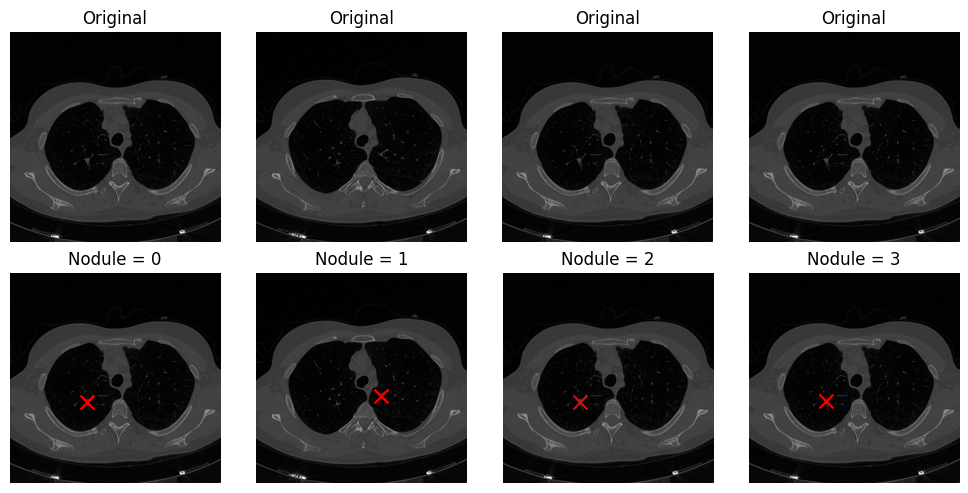

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    axes[0][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[0][i].set_title(f"Original")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[1][i].set_title(f"Nodule = {i}")
    axes[1][i].scatter(nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], c='red', marker='x', s=100)  # marca a posição do nódulo
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By comparing the original CT slice with the annotated nodule, we confirm that it does, indeed, correspond to the location of a nodule. However, for this CT Scan, we also understand that nodules 0, 2 and 3 are the same - they were simply marked by 3 different radiologists. This can be confirmed both by their 'FindingID' and by taking a closer look at the nodules. The <strong>'utils.py'</strong> module has a function which extracts a small region of an image (typically 80x80x80 voxels) surrounding a central point. This makes it very easy to get a centered image of each nodule!
  </p>
</div>

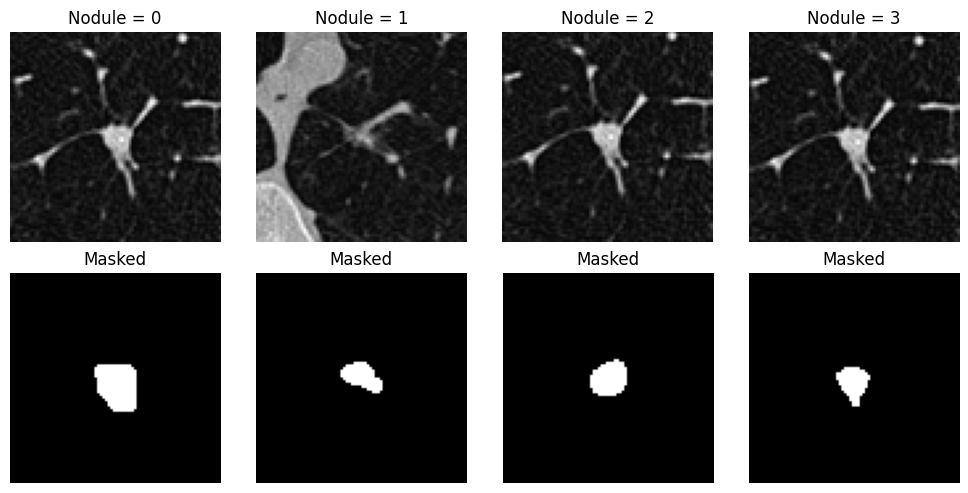

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    cube = utils.extractCube(scan, spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    mask_cube = utils.extractCube(nods_scan['mask'].iloc[i], spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    axes[0][i].imshow(cube[cube.shape[0]//2], cmap='gray')
    axes[0][i].set_title(f"Nodule = {i}")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(mask_cube[mask_cube.shape[0]//2], cmap = 'gray')
    axes[1][i].set_title(f"Masked")
    axes[1][i].axis("off")

plt.tight_layout()
plt.show() 
# Adjust spacing and display


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    And, as it is very clear now, there are 3 repeated nodules. This repetitions happens because the file <strong>'trainNodules.csv'</strong> has an entry for each finding made by a radiologist. So, if many radiologists annotate the same nodule, there are many rows corresponding to that node in the file. The radiologists annotated the nodule's mask pretty differently, even if it is exactly the same nodule. This is, actually, an important part of our pre-processing: we must decide how to deal with different subjective annotations for the same nodule.
  </p>
  <p>
    This repetition of the same nodule also happens in another file available in our dataset: <strong>chars_trainNodules.csv</strong>. In fact, these two complement eachother! The first stores the (x, y, z) coordinates of each finding, the nodule classification (nodule / non-nodule) and the volume and texture (necessary for calculating Fleischner Score). The second stores the subjective characteristics of each nodule (calcification, internal structure, malignancy, ...). So, it is a good idea to join them in one single file.
  </p>
  <p>
    However, there is a small detail to take into account - there is disparity line-wise in these files. <strong> chars_trainNodules.csv</strong> contains records from all 5 radiologists, while <strong>trainNodules.csv</strong> only contains records from radiologists 1, 2 and 3. This happens because, in the second file, the 'RadID' is relative to the CT Scan, and not to the overall ID of the radiologist. This can be handled by simply merging both tables while deleting duplicate columns and keeping the correct 'RadID_Real' relative to the overall radiologist ID instead of to the CT scan radiologist ID.
  </p>
</div>

In [4]:
char_train= pd.read_csv(find_file('chars_trainNodules.csv'))
train = pd.read_csv(find_file('trainNodules.csv'))

# Positional join: only valid if lines correspond to the same finding
assert len(train) == len(char_train)
assert (train[['LNDbID', 'FindingID']].values == char_train[['LNDbID', 'FindingID']].values).all()

combined_df = pd.concat([train, char_train.drop(columns=['LNDbID', 'FindingID']).rename(columns={'RadID': 'RadID_real'})],axis=1,)
combined_df['RadID_real'] = combined_df['RadID_real'].astype(int)

# 'outer' keeps all entries, 'inner' keeps only nodules present in both.
#combined_df = pd.merge(train, char_train, on=['LNDbID', 'RadID', 'FindingID'], how="outer")

print(combined_df.shape)
print(" | ".join(combined_df.columns))

(1527, 18)
LNDbID | RadID | FindingID | x | y | z | Nodule | Volume | Text | RadID_real | calcification | internalStructure | lobulation | malignancy | margin | sphericity | spiculation | subtlety


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Now, let us take a moment to understand the meaning of each column in our dataframe. We must have a clear understanding of our data so that we can make better processing choices and achieve better accuracy on our final predictions.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Each line corresponds to a finding <strong style="color: #c25719;">FindingID</strong> marked by a radiologist <strong style="color: #c25719;">RadID_Real</strong> in a scan <strong style="color: #c25719;">LNDbID</strong>.</li>
    <li style="margin-bottom: 8px;">We have the coordinates <strong style="color: #c25719;">x</strong>, <strong style="color: #c25719;">y</strong> and <strong style="color: #c25719;">z</strong> of our finding.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule</strong> is 1 if the finding is a nodule, and 0 if it is not.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Volume</strong> is the physical 3D volume of the annotated pulmonary lesion, measured in cubic millimeters.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Text</strong> refers to the texture of the nodule, and, combined with Volume, allows for Fleischner Score calculations.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Calcification</strong> refers to calcium deposits inside the nodule. Calcifications can be concentric rings, as well as off-centered or tiny scattered specks.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule consists of; specifically, its tissue density and components. It can be <strong>solid</strong>, <strong>subsolid</strong>, <strong>part-solid</strong>... Also, <strong>fat</strong> inside a nodule strongly favors a benign hamartoma, while <strong>cavitations</strong> warrant careful evaluation.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Lobulation</strong> refers to a wave-like outer contour instead of a smooth circle. Lobulated margins occur due to uneven growth rates in different parts of the nodule.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Malignancy</strong> categorizes on a scale from 1 to 5 the overall probability that the nodule is cancerous based on size, growth rate and physical features.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Margin</strong> is the general appearance of the border where the nodule meets normal lung tissue. It can be <strong>smooth/well-defined</strong> or <strong>ill-defined/irregular</strong>.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Sphericity</strong> measures how closely the nodule resembles a 3D sphere versus an elongated or flat shape.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Spiculation</strong> refers to strands or "spikes" radiating outward from the edge of the nodule into surrounding lung tissue, giving it a starburst appearance.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Subtlety</strong> indicates how easy or difficult the nodule is to visually distinguish from surrounding structures (like normal blood vessels, chest wall, or diaphragm).</li>
  </ul>
  <p>
    However, these two files that we have just merged together are not the only ones - we have another file, <strong>allNods.csv</strong>. It is grouped by independent nodule. However, the information available in this file is very focused on the text reports, adding little information about the CT Scans. There is one new column which can be valuable to us: <strong>'Lobe'</strong> column tells us where a nodule is located in the lung. So, we can consider this column for our model's predictions. 
  </p>
  <p>
    Let us extract the useful information from <strong>allNods.csv</strong>, by removing text report lines and extracting our column of interest, <strong>'Lobe'</strong>. To merge this column with our other files, we must take into account the fact that this file groups annotations by independent nodule.
  </p>
</div>

In [5]:
all_nods = pd.read_csv(find_file('allNods.csv'))
all_nods = all_nods[all_nods['Where'].str.contains("RadAnnotation", na=False)]
all_nods = all_nods[['LNDbID', 'FindingID', 'Lobe']]

combined_df = combined_df.merge(
    all_nods[["LNDbID", "FindingID", "Lobe"]],
    on=["LNDbID", "FindingID"],
    how="left",
)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    It is now time to join all the relevant information in a new file, which will be shared with LIDC-IDRI dataset and will be used to make predictions. We'll use the information in our combined dataframe of files <strong>trainNodules.csv</strong> and <strong>chars_trainNodules.csv</strong>, for the main subjective characteristics. 
  </p>
  <p> 
    We can also calculate the nodule diameter from the volume using the function nodEqDiam (available in file <strong>readNoduleList.py</strong>), which assumes the nodule is a sphere and calculates its equivalent diameter using the formula: <em>d</em> = 2 &times; (3<em>V</em> / 4&pi;)<sup>1/3</sup></p>
  <p>
    For non-nodules, the volume is always a fixed value because only the centroid was marked and no segmentation was performed. It is not a real measurement, so we keep the diameter as <i>'NaN'</i> in these cases.
  </p>
  <p> 
    And, from the volume and the texture, we can calculate the Fleischner score. This score is an automated patient-level categorization algorithm derived from the 2017 Fleischner Society guidelines. It converts the radiologist annotations for Volume and Texture across all detected nodules into a discrete score representing the clinical follow-up protocol for the patient. In the context of LNDb, it ranges from 0 (no routine follow-up) to 3 (high urgency). There is already a script <strong>calcFleischner.py</strong> provided with the dataset that does the calculations for us.
</div>

In [6]:
combined_df['diam_mm'] = combined_df['Volume'].apply(nodEqDiam)
combined_df.loc[combined_df['Nodule'] == 0, 'diam_mm'] = np.nan

header = ["LNDbID", "Nodule", "Volume", "Text"]
def get_per_nodule_score(row):
    # Pass a single nodule as a 1-row data list to calcFleischner
    nodule_data = [[row["LNDbID"], row["Nodule"], row["Volume"], row["Text"]]]
    res = calcFleischner([header] + nodule_data)
    # Extract score value from result
    if isinstance(res, list) and len(res) > 0:
        return res[1][1]  # Get last column (score) from returned row
    return res

# Suppress prints during the call
with open(os.devnull, "w") as f:
    with redirect_stdout(f):
        combined_df["Fleischner"] = combined_df.apply(get_per_nodule_score, axis=1)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    For every scan of the train set, we'll consider its nodules annotations for our final table. This table will be shared with the LIDC-IDRI dataset, so some variable names must be adapted in order to reflect its true meaning and allow for integration with LIDC-IDRI. If everything works out fine, we should have 236 CT Scans processed without any error message.
  </p>
</div>

In [7]:
scan_ids = pd.read_csv(find_file('trainCTs.csv'))
found = 0
not_found = 0
all = []
for id in scan_ids['LNDbID'].astype(int):
    try:
            _, _, _, nods = read_nods_in_scan(id, combined_df, load_images=False) # only the coordinates are needed here
            all.append(nods)
            found += 1
    except FileNotFoundError: not_found += 1
    except Exception as e: print(f'Error for scan {id}: {e}')

print(f'{found} files found, {not_found} files not found')

236 files found, 0 files not found


In [8]:
table = pd.concat(all, ignore_index=True)
table_csv = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': table['LNDbID'],
    'finding_id': table['FindingID'],
    'x': table['x_img'],
    'y': table['y_img'],
    'z': table['z_img'],
    'category': table['Nodule'],
    'calcification': table['calcification'],
    'internalstructure': table['internalStructure'],
    'lobulation': table['lobulation'],
    'margin': table['margin'],
    'sphericity': table['sphericity'],
    'spiculation': table['spiculation'],
    'subtlety': table['subtlety'],
    'malignancy': table['malignancy'], 
    'lobe': table['Lobe'],
    'volume': table['Volume'],
    'texture': table['Text'],
    'diam_mm': table['diam_mm'],
    'fleischner': table['Fleischner'],
})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    We must do a few changes to our columns and rows... first of all, we must not consider non-nodules; so, we drop rows where <strong>'category'</strong> value is 0. We must also change values in columns 'malignancy', 'lobulation' and 'spiculation' from 0 to NaN - since their scale is from 1 to 5, and the very low percentage of 0 indicates these values were errors or simply not filled in. Then, as we are doing a prediction by individual nodule, we must group our results considering all the different radiologists' predictions for the same nodule. For that, we'll use different methods depending on the information we want to extract from each variable.
  </p>
  <p>
    For example, where we have segmentation masks for different radiologists, which were used for the calculation of the nodule's volume, there are very different segmentations and, so, a great variance between the volumes for the same exact nodule. In cases where the value range is very high, we must analyze the values and choose the value accordingly.
  </p>
  <p>
    For most parameters, we'll use a special function <strong>'aggregate_columns'</strong> which will adapt our result based on the different scenarios and combinations of values attributed by radiologists.
  </p>
</div>

In [9]:
table_csv = table_csv[table_csv['category'] == 1]
cols = ['malignancy', 'lobulation', 'spiculation']
table_csv[cols] = table_csv[cols].replace(0, np.nan)

def aggregate_columns(series, start_value = None, end_value = None, mode = "characteristic"):
    vals = sorted(series.dropna()) #Get sorted values
    if not vals: return np.nan #If it is emptly, return NaN
    if len(set(vals)) == 1: return vals[0] #If only one value, return it
    val_range = max(vals) - min(vals) #Range in classifications
    match mode:
        case "coordinate":
            if val_range < 3.0 or len(vals) == 2: return np.mean(vals)
            range_1 = abs(vals[0] - vals[1])
            range_2 = abs(vals[1] - vals[2])
            range_3 = abs(vals[0] - vals[2])
            if range_1 < 3.0: return np.mean([vals[0], vals[1]])
            if range_2 < 3.0: return np.mean([vals[1], vals[2]])
            if range_3 < 3.0: return np.mean([vals[0], vals[2]])
            return np.mean(vals)
        case "volume":
            relative_diff = val_range / min(vals) if min(vals) > 0 else 0
            if relative_diff <= 0.3 or len(vals) == 2: return np.mean(vals)
            diff_1 = abs(vals[0] - vals[1]) / min([vals[0], vals[1]]) 
            diff_2 = abs(vals[1] - vals[2]) / min([vals[1], vals[2]])
            diff_3 = abs(vals[0] - vals[2]) / min ([vals[0], vals[2]])
            if diff_1 <= 0.3: return np.mean([vals[0], vals[1]])
            if diff_2 <= 0.3: return np.mean([vals[1], vals[2]])
            if diff_3 <= 0.3: return np.mean([vals[0], vals[2]])
            return np.median(vals)
        case "characteristic":
            middle_value = np.ceil((end_value - start_value)/2) #Defines separation point between high and low values
            if val_range >= end_value - start_value - 1: # Handle large discrepancies
                if vals.count(max(vals)) == 2: return max(vals) #If majority is the max value, use it
                if vals.count(min(vals)) == 2: return min(vals) + 1 #If majority is the min value, use it (plus 1 to prioritize detecting classification severity)
                #If there are 3 different values, use the dominant high/low values
                high_vals = [v for v in vals if v > middle_value] #High classifications
                low_vals = [v for v in vals if v < middle_value] #Low classifications
                if len(high_vals) > 1: return np.mean(high_vals) # Use the mean of the high values
                if len(low_vals) > 1: return max(low_vals) # Use the max of the low values to prioritize detecting classification severity
                return middle_value #Return middle value if high/low value counts are balanced
            return series.mean() #If there is not a big range in classifications, use the mean.

grouped_csv = table_csv.groupby(['scan_id', 'finding_id'], as_index=False).agg({
    'dataset' : 'first',
    'x': lambda s: aggregate_columns(s, mode = "coordinate"),
    'y': lambda s: aggregate_columns(s, mode = "coordinate"),
    'z': lambda s: aggregate_columns(s, mode = "coordinate"),
    'category': 'first',
    'calcification': lambda s: aggregate_columns(s, start_value=1, end_value=6),
    'internalstructure': lambda s: aggregate_columns(s, start_value=1, end_value=4),
    'lobulation': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'margin': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'sphericity': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'spiculation': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'subtlety': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'malignancy': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'lobe': lambda x: x.mode()[0],                   
    'volume': lambda s: aggregate_columns(s, mode = "volume"),        
    'texture': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'diam_mm': lambda s: aggregate_columns(s, mode = "coordinate"),
    'fleischner': lambda s: aggregate_columns(s, start_value=0, end_value=3),
    })

In [10]:
grouped_csv.to_csv('lndb_processed.csv', index=False)
print('Saved successfully:', grouped_csv.shape)

Saved successfully: (659, 20)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Regarding our custom aggregation function, we have considered slightly different measures for different data types.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule coordinates:</strong> if the distance between annotated coordinates is less than 3 voxels, we use the mean value. However, for a big range of values, we consider the furthest to be an outlier if the other two are close to eachother, and ignore it in the calculation of the mean.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Volume:</strong> We accept a difference as high as 30% between values (following the norms of medical measurements). If it is higher, we use the median instead of the mean, to avoid outlier values to affect our results.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Visual Characteristics:</strong>  If there is a big disagreement between radiologists, we give preference to a slightly higher result to guarantee that alarming values are not ignored by performing a simple mathematical mean. If the values tend to be high, we use only the high values for the mean. If the values tend to be low, we use the maximum of the low values. If two radiologists gave the same value but a 3rd disagrees, we use the most common value.</li>
  </ul>
  <p>
    Every nodule is characterized now. We have 659 indivudual nodules, by CT Scan, usable for our predictions. In total, we have 212 CT Scans with at least one nodule, with an average of 3.1 nodules per scan. 
  </p>
</div>

In [11]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from src.mass_detect.note.config import LNDB_DIR as LNDB
import ast
import math
import numpy as np
import pandas as pd
from src.mass_detect.note.config import LNDB_NODULES_FILE
from src.mass_detect.note.schema import SCHEMA, equivalent_diameter

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LNDb
  </h3>
  <p>
    The LNDb information is spread over three files that describe the same readings with different keys:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">'trainNodules.csv' has 1527 rows, with one row per reading (radiologist and finding). 'RadID' is the radiologist index inside the CT, from 1 to 3.</li>
    <li style="margin-bottom: 8px;">'chars_trainNodules.csv has 1527 rows, and contains the ratings (including malignancy). 'RadID' here is the global radiologist, from 1 to 5.</li>
    <li style="margin-bottom: 8px;">'trainNodules_gt.csv' has 1219 rows and has readings merged into unique findings, with position and volume. 'RadID' and 'RadFindingID' are comma separated lists.</li>
  </ul>
  <p>
  Joining the first two by 'RadID' silently mixes up ratings, which is what we have already discovered. Instead we join them by row position, after checking that the CT and the finding of every row agree and that the two radiologist numberings map one to one inside each CT.
  </p>
  <p>
    We'll also use 'trainNodules_gt.csv'. It stores, for each unique finding, the list of radiologists that read it and the list of their finding numbers. We expand these lists into one row per reading, look up the rating of each reading and average per finding.
  </p>
</div>

In [12]:
train_nodules = pd.read_csv(LNDB / "LNDb_csvs" / "trainNodules.csv")
chars = pd.read_csv(LNDB / "data" / "chars_trainNodules.csv")
merged_findings = pd.read_csv(LNDB / "LNDb_csvs" / "trainNodules_gt.csv")

# The two reading level files must have the same rows in the same order
assert len(train_nodules) == len(chars)
same_ct = train_nodules["LNDbID"].to_numpy() == chars["LNDbID"].astype(int).to_numpy()
same_finding = train_nodules["FindingID"].to_numpy() == chars["FindingID"].astype(int).to_numpy()
assert same_ct.all() and same_finding.all()

# Inside each CT, a local radiologist number must always match the same global one
pairs = pd.DataFrame({"ct": train_nodules["LNDbID"],
                      "local_rad": train_nodules["RadID"],
                      "global_rad": chars["RadID"].astype(int)}).drop_duplicates()
assert not pairs.duplicated(["ct", "local_rad"]).any()
assert not pairs.duplicated(["ct", "global_rad"]).any()

# One row per reading, with its malignancy rating (0 means not filled in)
readings = train_nodules[["LNDbID", "RadID", "FindingID"]].copy()
readings["malignancy"] = chars["malignancy"].replace(0, np.nan).to_numpy()
readings.head(10)

,LNDbID,RadID,FindingID,malignancy
0,1,1,1,2.0
1,1,1,2,2.0
2,1,2,1,2.0
3,1,3,1,2.0
4,2,1,1,1.0
5,2,1,2,1.0
6,2,1,3,3.0
7,2,1,4,2.0
8,2,1,5,2.0
9,2,2,1,1.0


In [13]:
# Expand the comma separated lists, for example RadID "1,2,3" and RadFindingID "1,1,3"
expanded = []
for finding in merged_findings.itertuples():
    rad_ids = str(finding.RadID).split(",")
    reading_ids = str(finding.RadFindingID).split(",")
    for rad_id, reading_id in zip(rad_ids, reading_ids):
        expanded.append({"LNDbID": finding.LNDbID,
                         "merged_finding": finding.FindingID,
                         "RadID": int(rad_id),
                         "FindingID": int(reading_id)})
expanded = pd.DataFrame(expanded)

# Every reading must find its row in the readings table, and none may be left over
expanded = expanded.merge(readings, on=["LNDbID", "RadID", "FindingID"], how="left", validate="many_to_one")
assert len(expanded) == len(train_nodules)
assert expanded["malignancy"].notna().sum() == chars["malignancy"].gt(0).sum()

# One row per unique finding, with the statistics of its ratings
grouped = expanded.groupby(["LNDbID", "merged_finding"])
ratings = grouped["malignancy"].agg(mal_mean="mean", mal_min="min", mal_max="max", n_rated="count")
ratings["n_readings"] = grouped.size()
ratings.head(10)

mal_mean  mal_min  mal_max  n_rated  n_readings
LNDbID merged_finding                                                 
1      1                    2.0      2.0      2.0        3           3
       2                    2.0      2.0      2.0        1           1
2      1                    1.0      1.0      1.0        3           3
       2                    1.0      1.0      1.0        2           2
       3                    2.5      2.0      3.0        2           2
       4                    2.0      2.0      2.0        1           1
       5                    2.0      2.0      2.0        1           1
       6                    1.0      1.0      1.0        1           1
       7                    2.0      2.0      2.0        1           1
       8                    1.0      1.0      1.0        1           1

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    There are two details to be taken care of:
  </p>
  <p>
  Volumes that are not measurements - when a radiologist only marked the centre of a finding, LNDb stores the volume of a 3 mm sphere. That affects all the non nodules and some small nodules. We flag them with 'volume_is_placeholder' and leave their volume and diameter empty, so nobody mistakes them for real sizes.
  </p>
  <p>
   The lobe - 'allNods.csv' has the lobe, but it was merged with a different procedure, so its 'FindingID' is not the same as in 'trainNodules_gt.csv'. We therefore match the lobe by position: for each finding we take the closest annotation of the same CT, and accept it if it is within 3 mm. The cell after the table checks how often the plain `FindingID` would have been wrong.
  </p>
</div>

In [14]:
LOBE_TOLERANCE_MM = 3.0

all_nods = pd.read_csv(LNDB / "data" / "allNods.csv")
all_nods = all_nods[all_nods["Where"].str.contains("RadAnnotation", na=False)]   # skip nodules only in reports

lobe = pd.Series(np.nan, index=merged_findings.index)
for ct_id, finding_rows in merged_findings.groupby("LNDbID"):
    candidates = all_nods[all_nods["LNDbID"] == ct_id]
    if candidates.empty:
        continue
    for index, finding in finding_rows.iterrows():
        offsets = candidates[["x", "y", "z"]].to_numpy() - np.array([finding["x"], finding["y"], finding["z"]])
        distances = np.linalg.norm(offsets, axis=1)
        if distances.min() <= LOBE_TOLERANCE_MM:
            lobe[index] = float(candidates["Lobe"].iloc[distances.argmin()])

In [15]:
# Scanner information per CT. Some columns hold lists written as text, for example "['Br64f', '3']".
acquisition = pd.read_csv(LNDB / "data" / "LNDbAcqParams.csv")

def first_item(text): # Returns the first element when the text is a list, otherwise the text itself.
    if isinstance(text, str) and text.startswith("["):
        return ast.literal_eval(text)[0]
    return text

scanner = pd.DataFrame({
    "LNDbID": acquisition["LNDbID"],
    "slice_thickness_mm": acquisition["SliceThickness"],
    "pixel_spacing_mm": acquisition["PixelSpacing"].map(lambda text: float(first_item(text))),
    "manufacturer": acquisition["Manufacturer"].str.upper().str.split().str[0],
    "model": acquisition["ManufacturerModelName"],
    "kernel": acquisition["ConvolutionKernel"].map(first_item),
    "kvp": acquisition["KVP"],
})

In [16]:
PLACEHOLDER_VOLUME = 4 * math.pi * 1.5 ** 3 / 3    # volume of a sphere with 3 mm of diameter

lndb = merged_findings.merge(ratings, left_on=["LNDbID", "FindingID"], right_index=True, how="left")
lndb["lobe"] = lobe

is_placeholder = np.isclose(lndb["Volume"], PLACEHOLDER_VOLUME)
lndb["volume_is_placeholder"] = is_placeholder
lndb["volume_mm3"] = lndb["Volume"].where(~is_placeholder)       # empty when it is not a measurement
lndb["diameter_mm"] = equivalent_diameter(lndb["volume_mm3"])

lndb["dataset"] = "LNDb"
lndb["scan_id"] = lndb["LNDbID"].map("LNDb-{:04d}".format)
lndb["patient_id"] = lndb["scan_id"]
lndb["nodule_uid"] = lndb["scan_id"] + "_" + lndb["FindingID"].astype(str)
lndb["is_nodule"] = lndb["Nodule"].astype(int)
lndb["reclustered"] = False
lndb["oversized_group"] = False
lndb = lndb.rename(columns={"x": "x_mm", "y": "y_mm", "z": "z_mm"})
lndb = lndb.merge(scanner, on="LNDbID", how="left", validate="many_to_one")
for column in ("vox_row", "vox_col", "vox_slice"):
    lndb[column] = np.nan
lndb = lndb[SCHEMA]

# The competition test CTs must never appear in the training table
test_scans = pd.read_csv(LNDB / "testCTs.csv")["LNDbID"].map("LNDb-{:04d}".format)
assert not set(test_scans) & set(lndb["scan_id"])

rated = lndb[(lndb["is_nodule"] == 1) & lndb["mal_mean"].notna()]
print(f"{len(lndb)} findings in {lndb['scan_id'].nunique()} CTs: "
      f"{lndb['is_nodule'].sum()} nodules and {(lndb['is_nodule'] == 0).sum()} non nodules")
print(f"{len(rated)} nodules have a rating, {(rated['n_rated'] > 1).sum()} of them by more than one radiologist")
print(f"Placeholder volumes: {is_placeholder.sum()} ({lndb.loc[lndb['is_nodule'] == 1, 'volume_is_placeholder'].sum()} of them nodules)")
print(f"Findings without a lobe: {lndb['lobe'].isna().sum()}")

# Why the lobe is matched by position: the same FindingID points to different places in the two files
same_id = merged_findings.merge(all_nods, on=["LNDbID", "FindingID"], suffixes=("_gt", "_all"))
shift = np.linalg.norm(same_id[["x_gt", "y_gt", "z_gt"]].to_numpy() - same_id[["x_all", "y_all", "z_all"]].to_numpy(), axis=1)
print(f"Same FindingID but more than 1 mm apart: {(shift > 1).sum()} of {len(same_id)} findings")

1219 findings in 229 CTs: 768 nodules and 451 non nodules
765 nodules have a rating, 221 of them by more than one radiologist
Placeholder volumes: 594 (143 of them nodules)
Findings without a lobe: 6
Same FindingID but more than 1 mm apart: 90 of 1152 findings


In [17]:
lndb.to_csv(LNDB_NODULES_FILE, index=False)
print("saved", lndb.shape, "->", LNDB_NODULES_FILE)

saved (1219, 28) -> /home/anasofia/labiacd/mass_detect/notebooks/lndb_nodules.csv
